In [1]:
import os
import pandas as pd


In [14]:
from common.configuration import DatasetPath, species_classes_map_all, species_by_familia, species_by_ordo
from common.stats import calculate_confusion_matrix, plot_confusion_matrix

In [3]:
all_classes = list(species_classes_map_all.keys())
all_classes

['Acer',
 'Alnus',
 'Apiaceae',
 'Artemisia',
 'Betula',
 'Chenopodiaceae',
 'Corylus',
 'Picea',
 'Pinus',
 'Plantago',
 'Poaceae',
 'Populus tremula',
 'Quercus',
 'Rumex',
 'Salix',
 'Tilia',
 'Urtica',
 'Ulmus',
 'Ambrosia',
 'Taraxacum',
 'Malus',
 'Unknown']

In [4]:
expert_estimation_excel_path = os.path.join(DatasetPath.real_historical_samples, "manual_analysis.xlsx")
expert_estimation_df = pd.read_excel(expert_estimation_excel_path, index_col=0).rename(columns={"Populus": "Populus tremula"}).fillna(0)
expert_estimation_df

,Corylus,Populus tremula,Alnus,Betula,Urtica,Salix,Acer,Ulmus,Pinus,Picea,Tilia,Plantago,Gramineae,Artemisia,Ambrosia,Chenopodiaceae,Apiaceae,Unknown,Rumex,Quercus
date,,,,,,,,,,,,,,,,,,,,
april 10,72,178,150,6,1,0,0,0,0,0,0,0,0,0,0,0,0,6,0,0.0
april 12,30,82,61,5,0,0,0,0,0,0,0,0,0,0,0,0,0,3,0,0.0
april 16,22,61,50,0,0,0,0,0,1,0,0,0,0,1,0,0,0,1,0,0.0
april 18,57,149,166,13,0,4,0,0,0,0,0,0,0,0,0,1,0,6,0,0.0
may 1,0,0,1,447,10,749,228,0,1,18,1,0,0,1,0,1,0,0,0,0.0
may 21,0,0,19,16,10,0,27,0,0,0,0,0,0,1,2,5,0,0,0,0.0
june 10,0,0,1,7,29,2,5,4,2,0,0,247,27,1,0,1,0,0,0,0.0
june 17,0,0,0,0,19,0,0,5,0,0,0,340,4,5,0,3,0,0,0,0.0
june 25,10,0,1,11,42,0,0,2,0,0,0,82,19,7,0,4,0,0,0,0.0


In [5]:
model_prediction_path = "Save/historical_predictions_summary.csv"
model_prediction_df = pd.read_csv(model_prediction_path, index_col=0).fillna(0)
model_prediction_df

,Betula,Unknown,Plantago,Poaceae,Ulmus,Apiaceae,Acer,Corylus,Salix,Artemisia,Chenopodiaceae,Alnus,Quercus,Rumex,Urtica,Ambrosia,Tilia,Picea,Populus tremula,Pinus
june 25,14.0,56,10.0,4.0,8.0,4.0,23.0,1.0,12.0,28,6.0,1.0,1.0,2.0,3.0,0.0,0.0,0.0,0.0,0.0
september 1,3.0,18,0.0,0.0,3.0,2.0,9.0,0.0,1.0,5,5.0,0.0,3.0,2.0,0.0,3.0,1.0,0.0,0.0,0.0
september 2,1.0,19,1.0,0.0,2.0,2.0,26.0,1.0,0.0,1,2.0,0.0,0.0,3.0,1.0,3.0,1.0,1.0,0.0,0.0
august 27,5.0,12,2.0,0.0,0.0,4.0,15.0,0.0,2.0,16,0.0,1.0,0.0,1.0,6.0,0.0,0.0,0.0,0.0,0.0
august 28,11.0,38,3.0,0.0,10.0,5.0,34.0,0.0,2.0,21,7.0,0.0,3.0,1.0,5.0,3.0,0.0,1.0,1.0,0.0
april 12,46.0,44,0.0,5.0,3.0,2.0,6.0,1.0,0.0,12,0.0,15.0,1.0,0.0,4.0,4.0,0.0,0.0,50.0,0.0
april 10,99.0,70,0.0,4.0,13.0,0.0,14.0,0.0,0.0,48,0.0,59.0,1.0,0.0,23.0,3.0,0.0,1.0,74.0,1.0
august 29,10.0,17,2.0,1.0,6.0,3.0,11.0,0.0,0.0,8,5.0,1.0,1.0,2.0,0.0,3.0,0.0,0.0,0.0,0.0
april 16,37.0,33,0.0,0.0,2.0,1.0,11.0,0.0,0.0,7,0.0,18.0,0.0,0.0,4.0,2.0,0.0,0.0,44.0,1.0
april 18,123.0,56,0.0,0.0,4.0,1.0,9.0,1.0,0.0,47,1.0,48.0,3.0,0.0,16.0,0.0,0.0,2.0,69.0,2.0


In [17]:
def analyze_performance_sample_data(true_labels: dict, pred_labels: dict, subtitle: str, all_classes: list[str], mapper: dict = None, plot=False):
    if mapper is not None:
        mapped_true_labels = {}
        mapped_pred_labels = {}
        for new_class in mapper.keys():
            mapped_true_labels[new_class] = sum([true_labels[x] for x in mapper[new_class] if x in true_labels])
            mapped_pred_labels[new_class] = sum([pred_labels[x] for x in mapper[new_class] if x in pred_labels])
        true_labels = mapped_true_labels
        pred_labels = mapped_pred_labels
    print("---Sample test---")
    print(
        f"True Total objets: {sum(true_labels.values())}, data: {true_labels}")
    print("-" * 10)
    print(
        f"Pred Total objets: {sum(pred_labels.values())}, data: {pred_labels}")
    confusion_matrices_df = calculate_confusion_matrix(
        true_labels, pred_labels, all_classes)
    
    if plot:
        plot_confusion_matrix(
            confusion_matrices_df.iloc[:, 0:3], subtitle=subtitle)
        for k in true_labels.keys():
            if true_labels[k] != 0:
                print(k, round(confusion_matrices_df["TP"].to_dict().get(
                    k, 0) / true_labels[k], 3))
            
    return confusion_matrices_df


In [31]:
def evaluate_aggregate_metrics(confusion_matrices_df: pd.DataFrame):
    total_samples = (confusion_matrices_df["TP"].sum() + confusion_matrices_df["FP"].sum())
    f1_score = 2 * confusion_matrices_df["TP"].sum() / (2 * confusion_matrices_df["TP"].sum() + confusion_matrices_df["FP"].sum() + confusion_matrices_df["FN"].sum())
    print(f"F1 Score: {f1_score}")


## Classification on Genus level

---Sample test---
True Total objets: 178.0, data: {'Corylus': 10.0, 'Populus tremula': 0.0, 'Alnus': 1.0, 'Betula': 11.0, 'Urtica': 42.0, 'Salix': 0.0, 'Acer': 0.0, 'Ulmus': 2.0, 'Pinus': 0.0, 'Picea': 0.0, 'Tilia': 0.0, 'Plantago': 82.0, 'Gramineae': 19.0, 'Artemisia': 7.0, 'Ambrosia': 0.0, 'Chenopodiaceae': 4.0, 'Apiaceae': 0.0, 'Unknown': 0.0, 'Rumex': 0.0, 'Quercus': 0.0}
----------
Pred Total objets: 173.0, data: {'Betula': 14.0, 'Unknown': 56.0, 'Plantago': 10.0, 'Poaceae': 4.0, 'Ulmus': 8.0, 'Apiaceae': 4.0, 'Acer': 23.0, 'Corylus': 1.0, 'Salix': 12.0, 'Artemisia': 28.0, 'Chenopodiaceae': 6.0, 'Alnus': 1.0, 'Quercus': 1.0, 'Rumex': 2.0, 'Urtica': 3.0, 'Ambrosia': 0.0, 'Tilia': 0.0, 'Picea': 0.0, 'Populus tremula': 0.0, 'Pinus': 0.0}
---Sample test---
True Total objets: 38.0, data: {'Corylus': 0.0, 'Populus tremula': 0.0, 'Alnus': 0.0, 'Betula': 0.0, 'Urtica': 4.0, 'Salix': 0.0, 'Acer': 0.0, 'Ulmus': 0.0, 'Pinus': 0.0, 'Picea': 0.0, 'Tilia': 0.0, 'Plantago': 0.0, 'Gramineae': 7.0

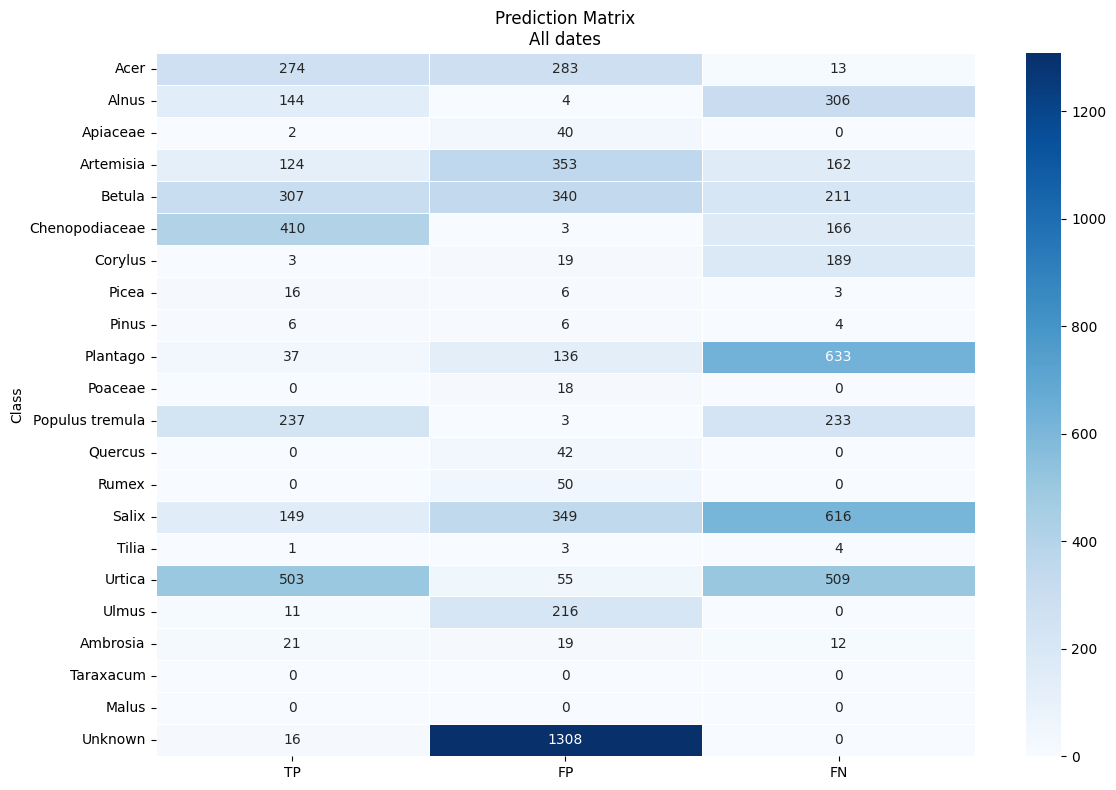

F1 Score: 0.417312661498708


In [32]:
full_confusion_matrices_df = None

for date_idx in model_prediction_df.index:
    prediction:dict = model_prediction_df.loc[date_idx].to_dict()
    groundtruth:dict = expert_estimation_df.loc[date_idx].to_dict()
    assert len(prediction) > 0
    assert len(groundtruth) > 0

    cf_df = analyze_performance_sample_data(groundtruth, prediction, date_idx, all_classes=all_classes)
    if full_confusion_matrices_df is None:
        full_confusion_matrices_df = cf_df
    else:
        full_confusion_matrices_df += cf_df
plot_confusion_matrix(
        full_confusion_matrices_df.iloc[:, 0:3], subtitle="All dates")

evaluate_aggregate_metrics(full_confusion_matrices_df)

## Classification on Familia level

---Sample test---
True Total objets: 159.0, data: {'Sapindaceae': 0.0, 'Betulaceae': 22.0, 'Ulmaceae': 2.0, 'Fagaceae': 0.0, 'Salicaceae': 0.0, 'Malvaceae': 0.0, 'Pinaceae': 0.0, 'Apiaceae': 0.0, 'Asteraceae': 7.0, 'Rosaceae': 0, 'Poaceae': 0, 'Chenopodiaceae': 4.0, 'Plantaginaceae': 82.0, 'Polygonaceae': 0.0, 'Urticaceae': 42.0}
----------
Pred Total objets: 117.0, data: {'Sapindaceae': 23.0, 'Betulaceae': 16.0, 'Ulmaceae': 8.0, 'Fagaceae': 1.0, 'Salicaceae': 12.0, 'Malvaceae': 0.0, 'Pinaceae': 0.0, 'Apiaceae': 4.0, 'Asteraceae': 28.0, 'Rosaceae': 0, 'Poaceae': 4.0, 'Chenopodiaceae': 6.0, 'Plantaginaceae': 10.0, 'Polygonaceae': 2.0, 'Urticaceae': 3.0}
---Sample test---
True Total objets: 31.0, data: {'Sapindaceae': 0.0, 'Betulaceae': 0.0, 'Ulmaceae': 0.0, 'Fagaceae': 0.0, 'Salicaceae': 0.0, 'Malvaceae': 0.0, 'Pinaceae': 0.0, 'Apiaceae': 0.0, 'Asteraceae': 22.0, 'Rosaceae': 0, 'Poaceae': 0, 'Chenopodiaceae': 5.0, 'Plantaginaceae': 0.0, 'Polygonaceae': 0.0, 'Urticaceae': 4.0}
----------

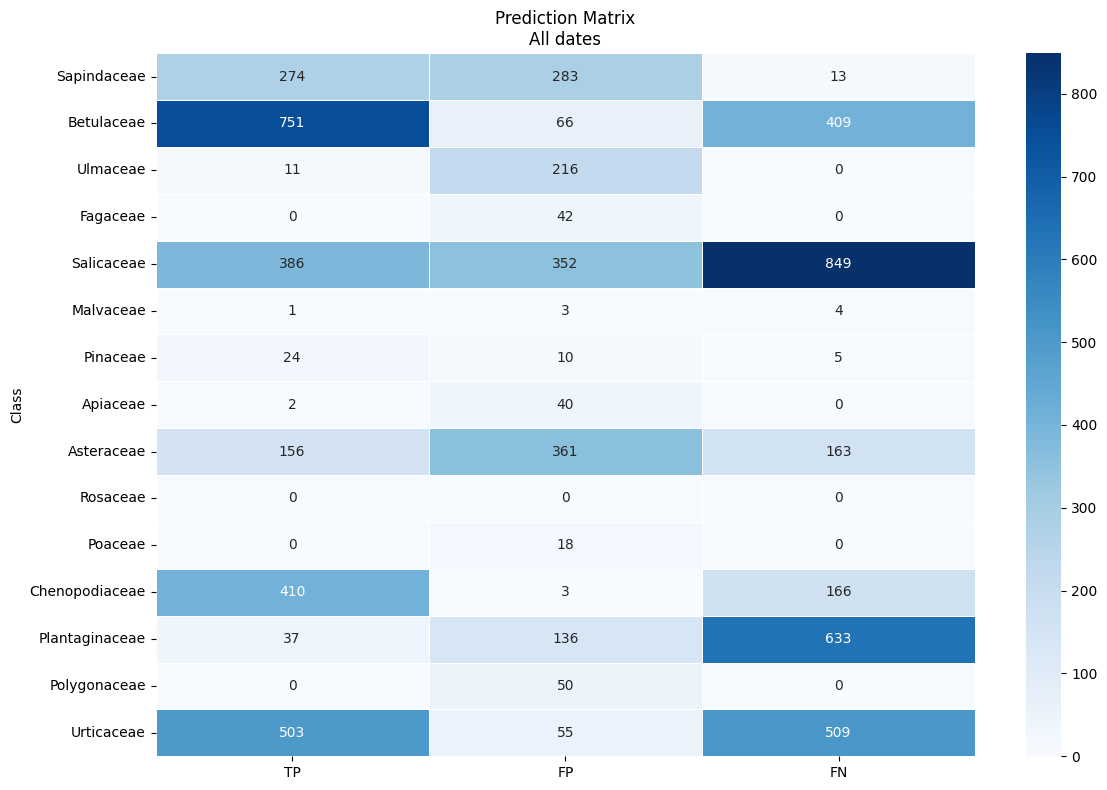

F1 Score: 0.5381213142375737


In [34]:
full_confusion_matrices_df = None

for date_idx in model_prediction_df.index:
    prediction:dict = model_prediction_df.loc[date_idx].to_dict()
    groundtruth:dict = expert_estimation_df.loc[date_idx].to_dict()
    assert len(prediction) > 0
    assert len(groundtruth) > 0

    cf_df = analyze_performance_sample_data(groundtruth, prediction, date_idx, all_classes=species_by_familia.keys(), mapper=species_by_familia)
    if full_confusion_matrices_df is None:
        full_confusion_matrices_df = cf_df
    else:
        full_confusion_matrices_df += cf_df
plot_confusion_matrix(
        full_confusion_matrices_df.iloc[:, 0:3], subtitle="All dates")

evaluate_aggregate_metrics(full_confusion_matrices_df)

## Classification on Ordo level

---Sample test---
True Total objets: 159.0, data: {'Sapindales': 0.0, 'Fagales': 22.0, 'Rosales': 44.0, 'Malpighiales': 0.0, 'Malvales': 0.0, 'Pinales': 0.0, 'Apiales': 0.0, 'Asterales': 7.0, 'Poales': 0, 'Caryophyllales': 4.0, 'Lamiales': 82.0}
----------
Pred Total objets: 117.0, data: {'Sapindales': 23.0, 'Fagales': 17.0, 'Rosales': 11.0, 'Malpighiales': 12.0, 'Malvales': 0.0, 'Pinales': 0.0, 'Apiales': 4.0, 'Asterales': 28.0, 'Poales': 4.0, 'Caryophyllales': 8.0, 'Lamiales': 10.0}


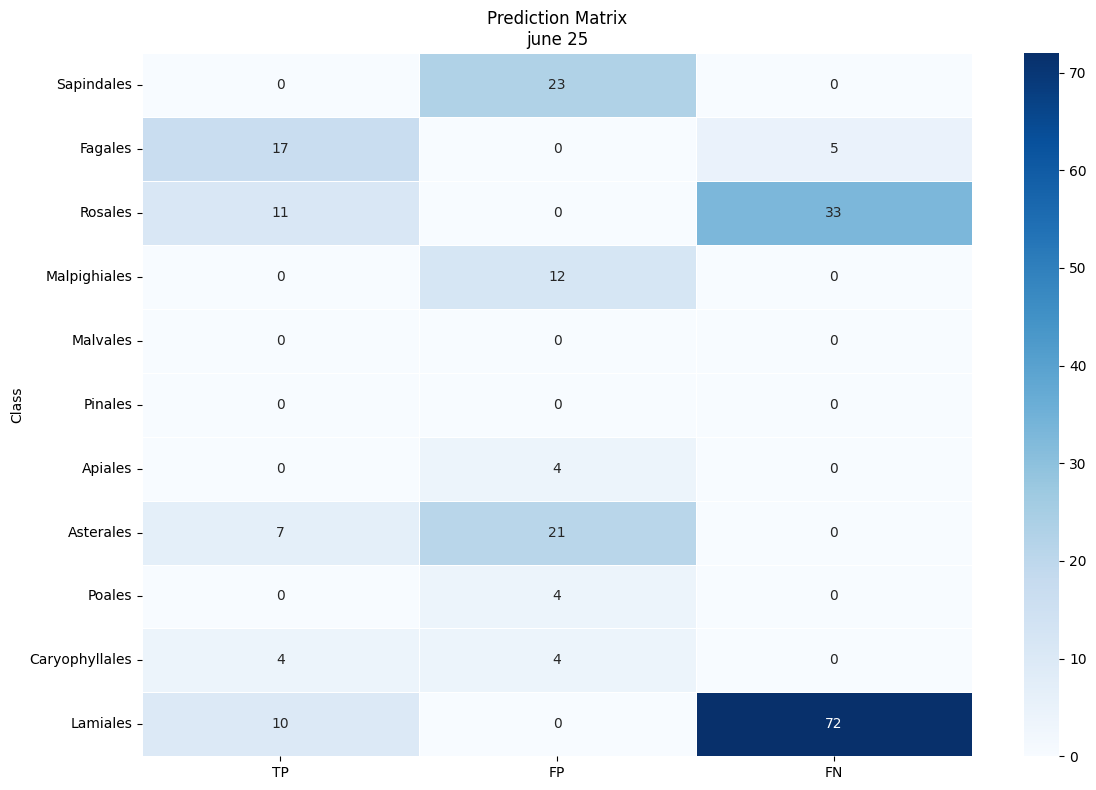

Fagales 0.773
Rosales 0.25
Asterales 1.0
Caryophyllales 1.0
Lamiales 0.122
---Sample test---
True Total objets: 31.0, data: {'Sapindales': 0.0, 'Fagales': 0.0, 'Rosales': 4.0, 'Malpighiales': 0.0, 'Malvales': 0.0, 'Pinales': 0.0, 'Apiales': 0.0, 'Asterales': 22.0, 'Poales': 0, 'Caryophyllales': 5.0, 'Lamiales': 0.0}
----------
Pred Total objets: 37.0, data: {'Sapindales': 9.0, 'Fagales': 6.0, 'Rosales': 3.0, 'Malpighiales': 1.0, 'Malvales': 1.0, 'Pinales': 0.0, 'Apiales': 2.0, 'Asterales': 8.0, 'Poales': 0.0, 'Caryophyllales': 7.0, 'Lamiales': 0.0}


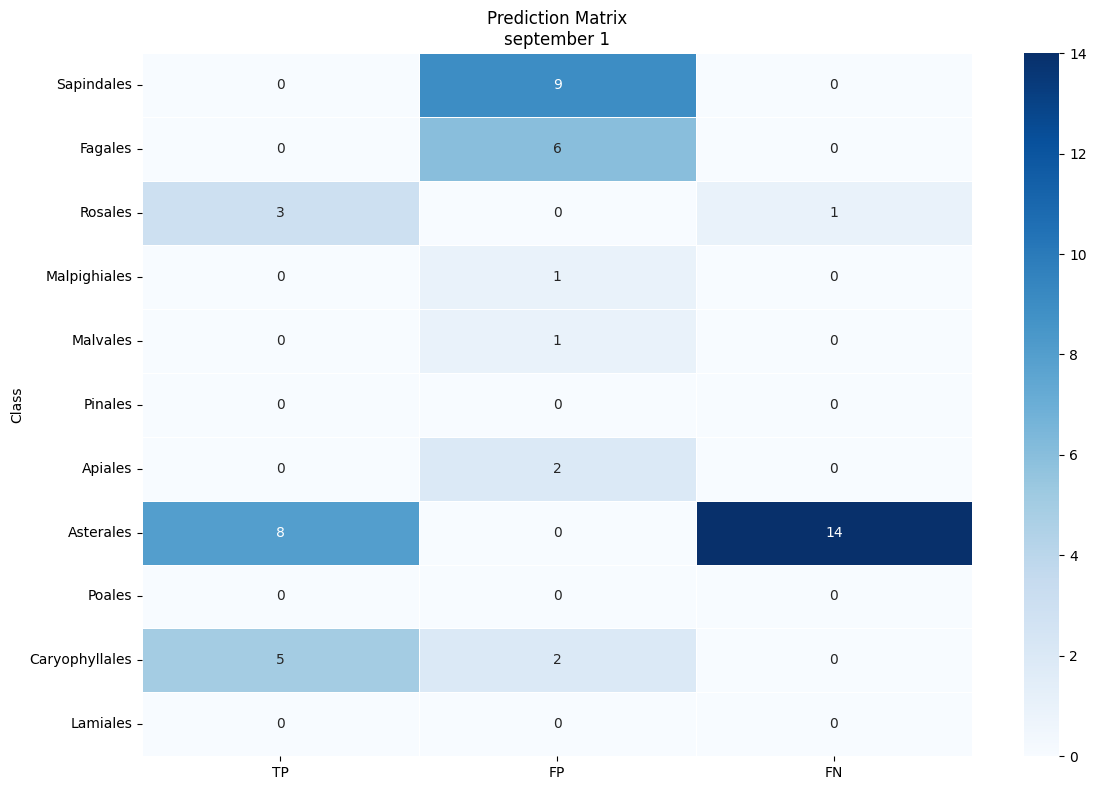

Rosales 0.75
Asterales 0.364
Caryophyllales 1.0
---Sample test---
True Total objets: 64.0, data: {'Sapindales': 27.0, 'Fagales': 2.0, 'Rosales': 14.0, 'Malpighiales': 0.0, 'Malvales': 1.0, 'Pinales': 1.0, 'Apiales': 1.0, 'Asterales': 13.0, 'Poales': 0, 'Caryophyllales': 5.0, 'Lamiales': 0.0}
----------
Pred Total objets: 45.0, data: {'Sapindales': 26.0, 'Fagales': 2.0, 'Rosales': 3.0, 'Malpighiales': 0.0, 'Malvales': 1.0, 'Pinales': 1.0, 'Apiales': 2.0, 'Asterales': 4.0, 'Poales': 0.0, 'Caryophyllales': 5.0, 'Lamiales': 1.0}


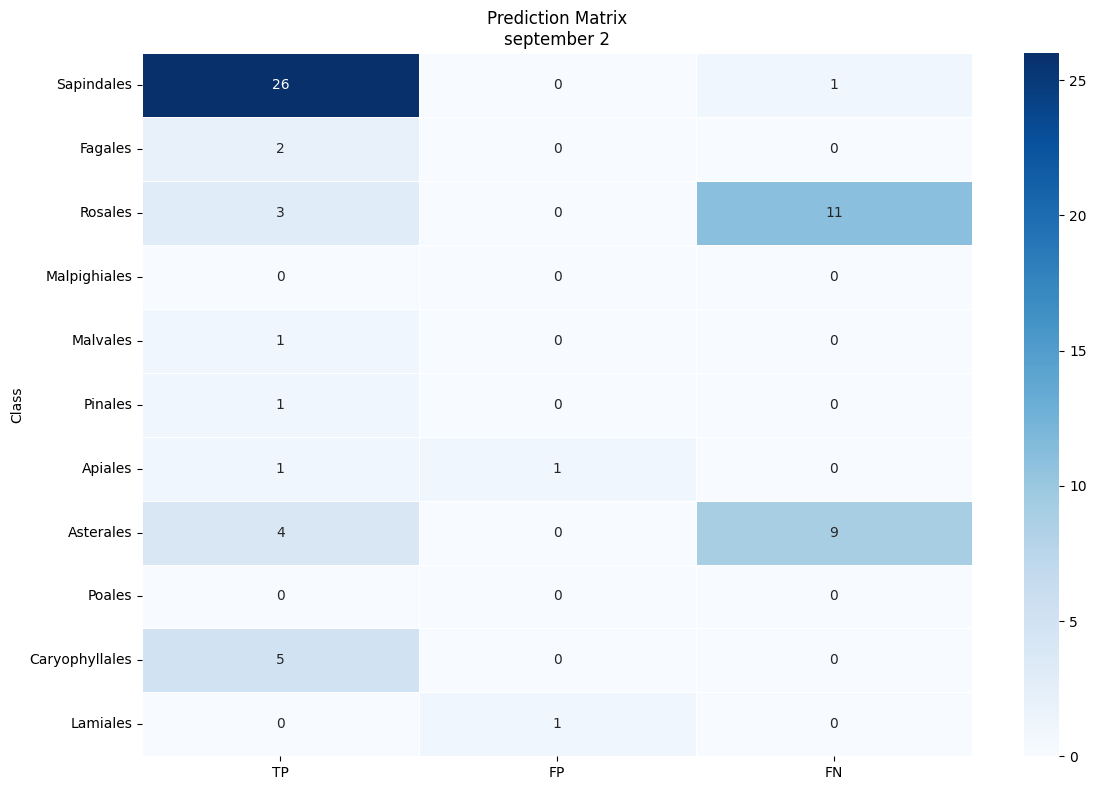

Sapindales 0.963
Fagales 1.0
Rosales 0.214
Malvales 1.0
Pinales 1.0
Apiales 1.0
Asterales 0.308
Caryophyllales 1.0
---Sample test---
True Total objets: 33.0, data: {'Sapindales': 0.0, 'Fagales': 0.0, 'Rosales': 13.0, 'Malpighiales': 0.0, 'Malvales': 0.0, 'Pinales': 0.0, 'Apiales': 0.0, 'Asterales': 19.0, 'Poales': 0, 'Caryophyllales': 1.0, 'Lamiales': 0.0}
----------
Pred Total objets: 52.0, data: {'Sapindales': 15.0, 'Fagales': 6.0, 'Rosales': 6.0, 'Malpighiales': 2.0, 'Malvales': 0.0, 'Pinales': 0.0, 'Apiales': 4.0, 'Asterales': 16.0, 'Poales': 0.0, 'Caryophyllales': 1.0, 'Lamiales': 2.0}


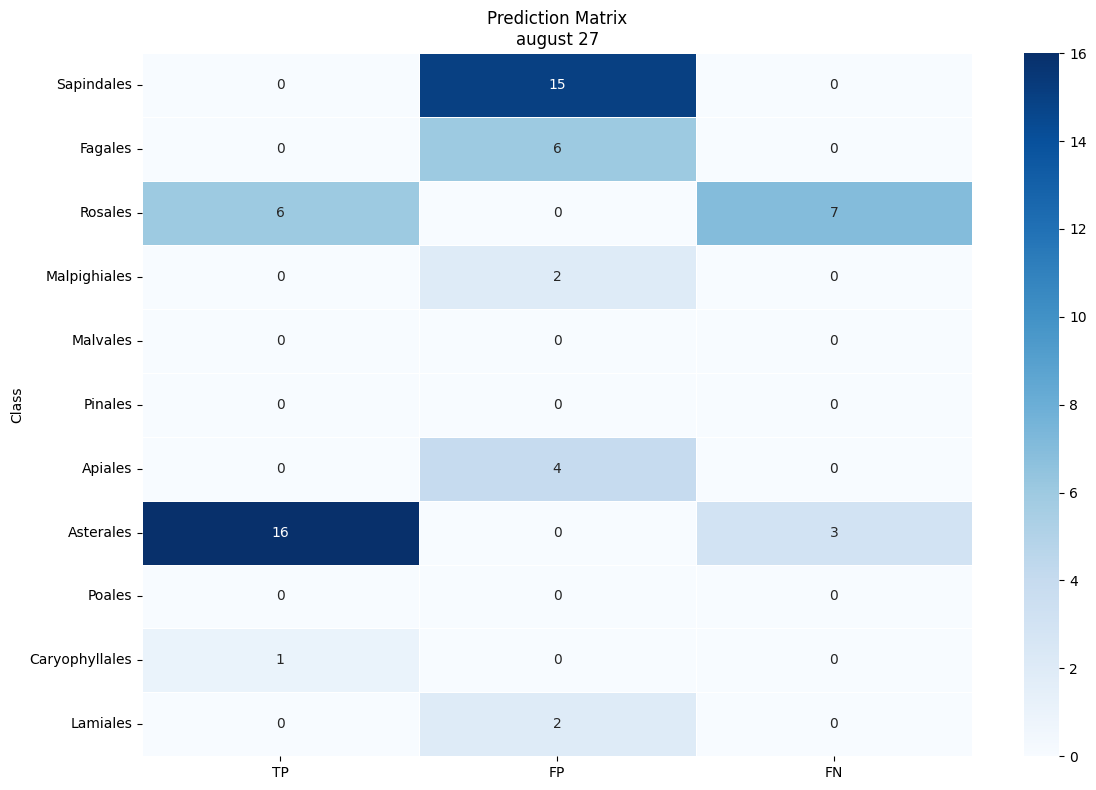

Rosales 0.462
Asterales 0.842
Caryophyllales 1.0
---Sample test---
True Total objets: 98.0, data: {'Sapindales': 0.0, 'Fagales': 5.0, 'Rosales': 14.0, 'Malpighiales': 0.0, 'Malvales': 1.0, 'Pinales': 1.0, 'Apiales': 0.0, 'Asterales': 66.0, 'Poales': 0, 'Caryophyllales': 11.0, 'Lamiales': 0.0}
----------
Pred Total objets: 107.0, data: {'Sapindales': 34.0, 'Fagales': 14.0, 'Rosales': 15.0, 'Malpighiales': 3.0, 'Malvales': 0.0, 'Pinales': 1.0, 'Apiales': 5.0, 'Asterales': 24.0, 'Poales': 0.0, 'Caryophyllales': 8.0, 'Lamiales': 3.0}


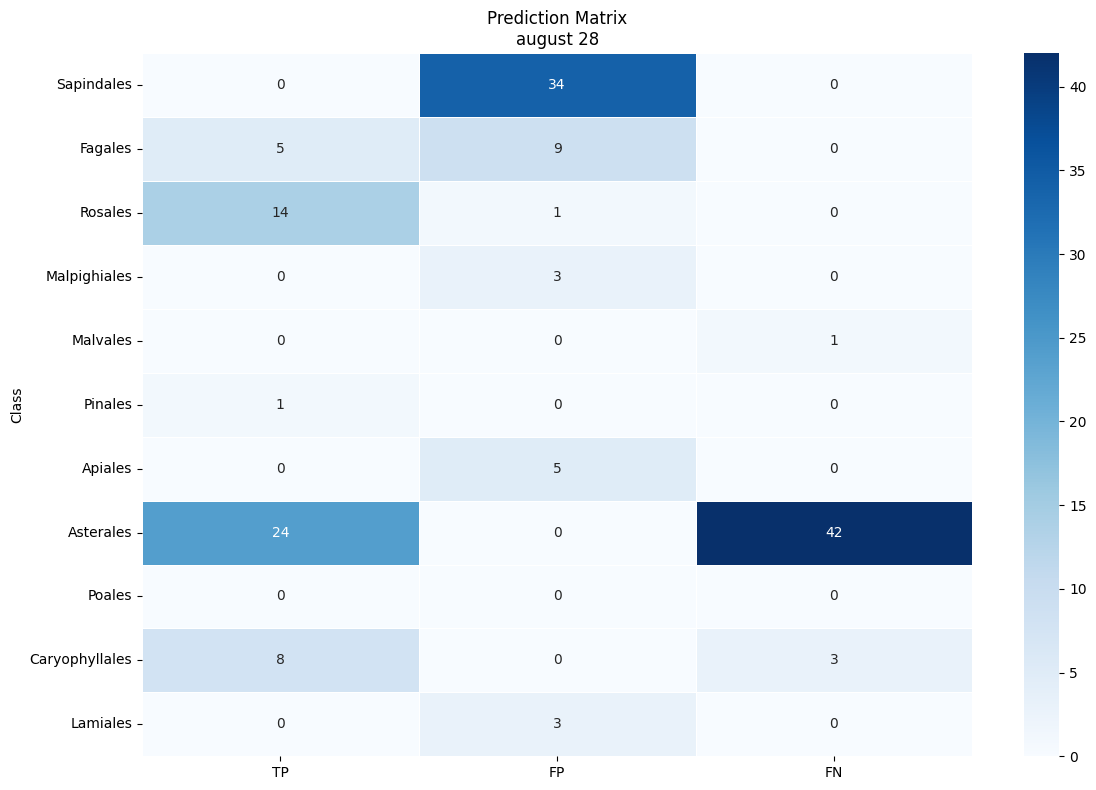

Fagales 1.0
Rosales 1.0
Malvales 0.0
Pinales 1.0
Asterales 0.364
Caryophyllales 0.727
---Sample test---
True Total objets: 178.0, data: {'Sapindales': 0.0, 'Fagales': 96.0, 'Rosales': 0.0, 'Malpighiales': 82.0, 'Malvales': 0.0, 'Pinales': 0.0, 'Apiales': 0.0, 'Asterales': 0.0, 'Poales': 0, 'Caryophyllales': 0.0, 'Lamiales': 0.0}
----------
Pred Total objets: 149.0, data: {'Sapindales': 6.0, 'Fagales': 63.0, 'Rosales': 7.0, 'Malpighiales': 50.0, 'Malvales': 0.0, 'Pinales': 0.0, 'Apiales': 2.0, 'Asterales': 16.0, 'Poales': 5.0, 'Caryophyllales': 0.0, 'Lamiales': 0.0}


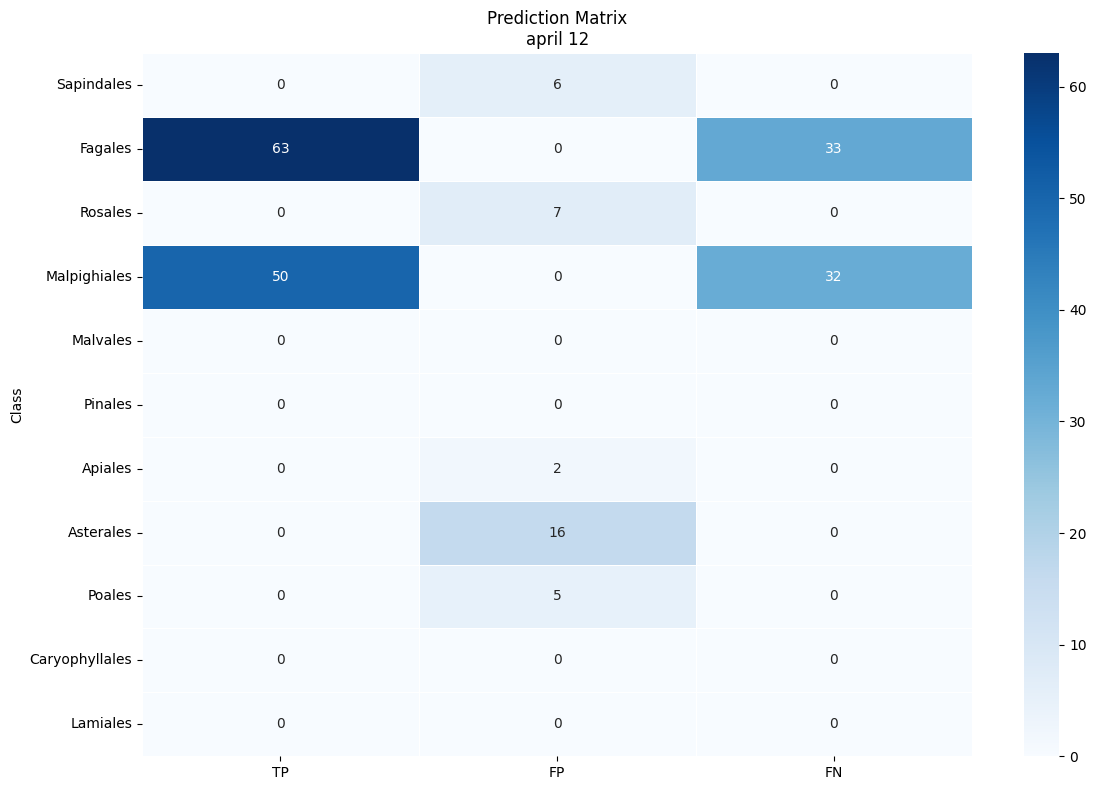

Fagales 0.656
Malpighiales 0.61
---Sample test---
True Total objets: 407.0, data: {'Sapindales': 0.0, 'Fagales': 228.0, 'Rosales': 1.0, 'Malpighiales': 178.0, 'Malvales': 0.0, 'Pinales': 0.0, 'Apiales': 0.0, 'Asterales': 0.0, 'Poales': 0, 'Caryophyllales': 0.0, 'Lamiales': 0.0}
----------
Pred Total objets: 340.0, data: {'Sapindales': 14.0, 'Fagales': 159.0, 'Rosales': 36.0, 'Malpighiales': 74.0, 'Malvales': 0.0, 'Pinales': 2.0, 'Apiales': 0.0, 'Asterales': 51.0, 'Poales': 4.0, 'Caryophyllales': 0.0, 'Lamiales': 0.0}


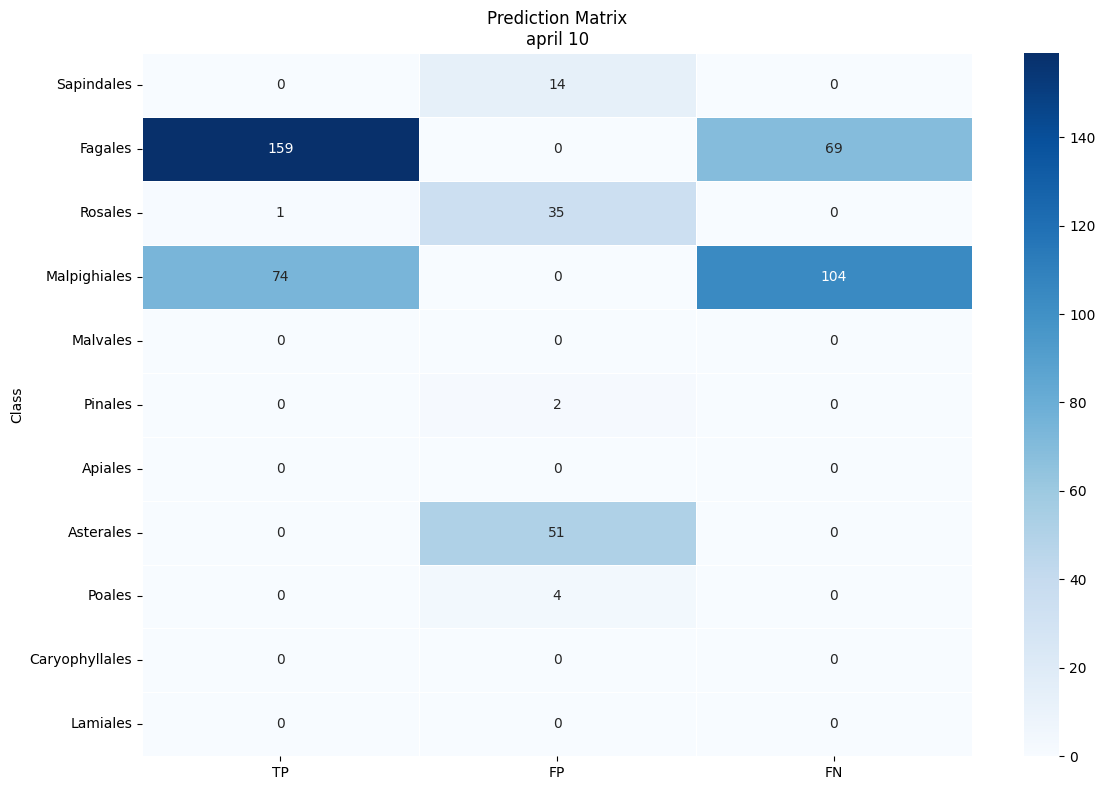

Fagales 0.697
Rosales 1.0
Malpighiales 0.416
---Sample test---
True Total objets: 54.0, data: {'Sapindales': 0.0, 'Fagales': 2.0, 'Rosales': 15.0, 'Malpighiales': 0.0, 'Malvales': 0.0, 'Pinales': 1.0, 'Apiales': 1.0, 'Asterales': 26.0, 'Poales': 0, 'Caryophyllales': 9.0, 'Lamiales': 0.0}
----------
Pred Total objets: 53.0, data: {'Sapindales': 11.0, 'Fagales': 12.0, 'Rosales': 6.0, 'Malpighiales': 0.0, 'Malvales': 0.0, 'Pinales': 0.0, 'Apiales': 3.0, 'Asterales': 11.0, 'Poales': 1.0, 'Caryophyllales': 7.0, 'Lamiales': 2.0}


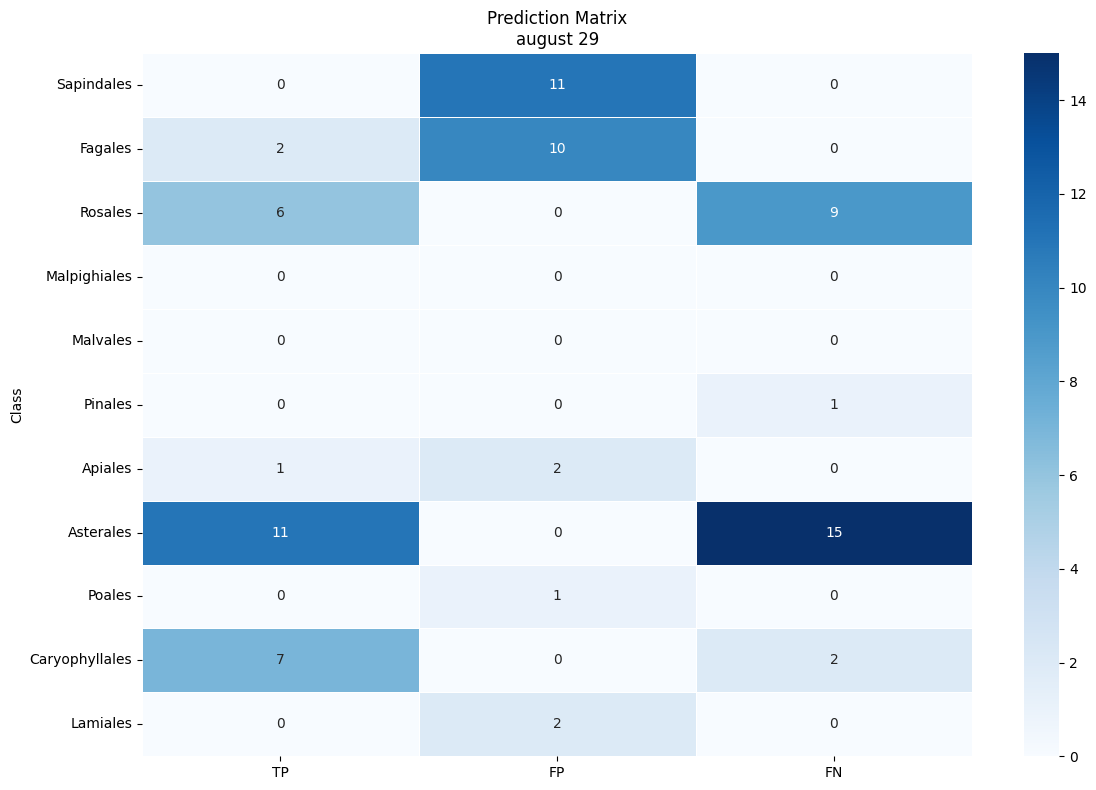

Fagales 1.0
Rosales 0.4
Pinales 0.0
Apiales 1.0
Asterales 0.423
Caryophyllales 0.778
---Sample test---
True Total objets: 135.0, data: {'Sapindales': 0.0, 'Fagales': 72.0, 'Rosales': 0.0, 'Malpighiales': 61.0, 'Malvales': 0.0, 'Pinales': 1.0, 'Apiales': 0.0, 'Asterales': 1.0, 'Poales': 0, 'Caryophyllales': 0.0, 'Lamiales': 0.0}
----------
Pred Total objets: 127.0, data: {'Sapindales': 11.0, 'Fagales': 55.0, 'Rosales': 6.0, 'Malpighiales': 44.0, 'Malvales': 0.0, 'Pinales': 1.0, 'Apiales': 1.0, 'Asterales': 9.0, 'Poales': 0.0, 'Caryophyllales': 0.0, 'Lamiales': 0.0}


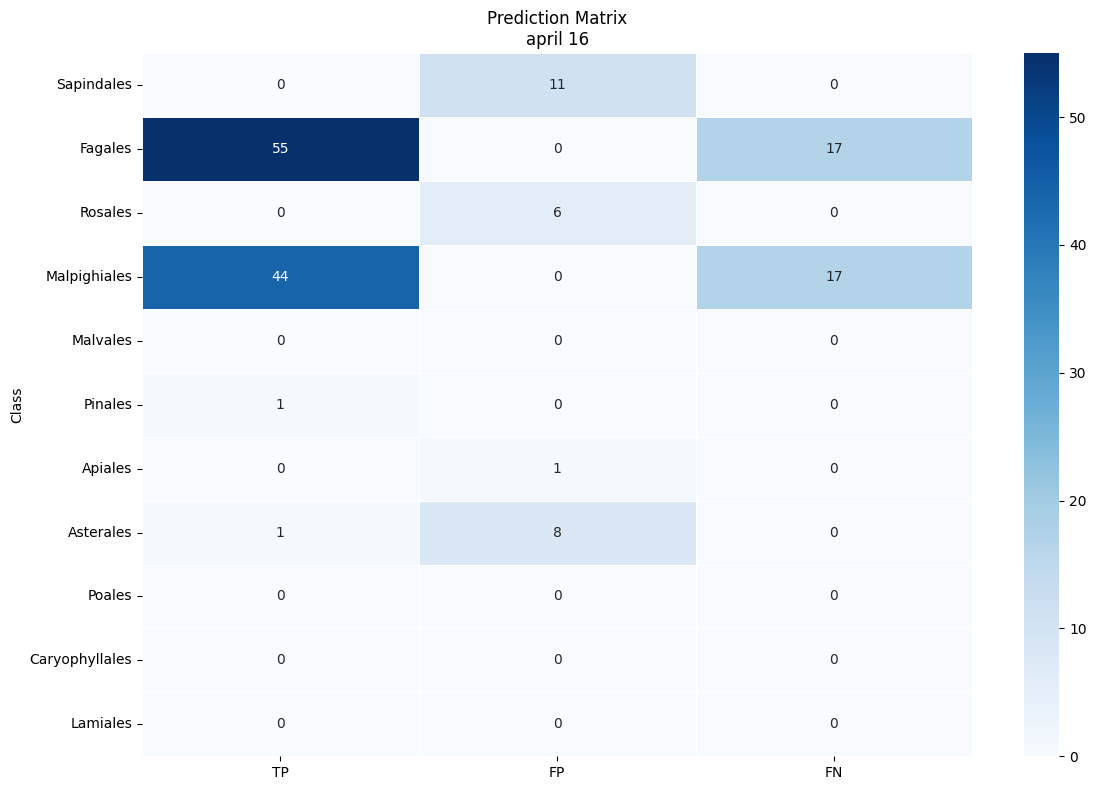

Fagales 0.764
Malpighiales 0.721
Pinales 1.0
Asterales 1.0
---Sample test---
True Total objets: 390.0, data: {'Sapindales': 0.0, 'Fagales': 236.0, 'Rosales': 0.0, 'Malpighiales': 153.0, 'Malvales': 0.0, 'Pinales': 0.0, 'Apiales': 0.0, 'Asterales': 0.0, 'Poales': 0, 'Caryophyllales': 1.0, 'Lamiales': 0.0}
----------
Pred Total objets: 326.0, data: {'Sapindales': 9.0, 'Fagales': 175.0, 'Rosales': 20.0, 'Malpighiales': 69.0, 'Malvales': 0.0, 'Pinales': 4.0, 'Apiales': 1.0, 'Asterales': 47.0, 'Poales': 0.0, 'Caryophyllales': 1.0, 'Lamiales': 0.0}


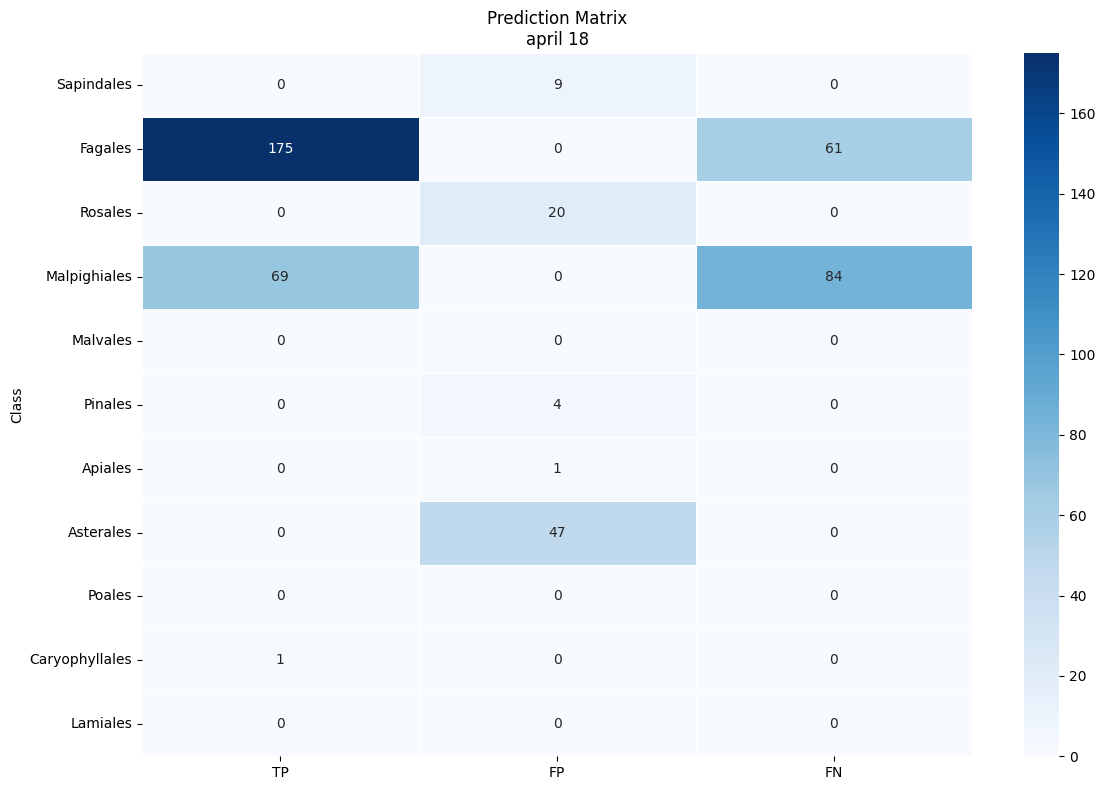

Fagales 0.742
Malpighiales 0.451
Caryophyllales 1.0
---Sample test---
True Total objets: 172.0, data: {'Sapindales': 0.0, 'Fagales': 4.0, 'Rosales': 27.0, 'Malpighiales': 0.0, 'Malvales': 1.0, 'Pinales': 3.0, 'Apiales': 0.0, 'Asterales': 122.0, 'Poales': 0, 'Caryophyllales': 15.0, 'Lamiales': 0.0}
----------
Pred Total objets: 161.0, data: {'Sapindales': 43.0, 'Fagales': 29.0, 'Rosales': 19.0, 'Malpighiales': 2.0, 'Malvales': 0.0, 'Pinales': 2.0, 'Apiales': 5.0, 'Asterales': 42.0, 'Poales': 0.0, 'Caryophyllales': 9.0, 'Lamiales': 10.0}


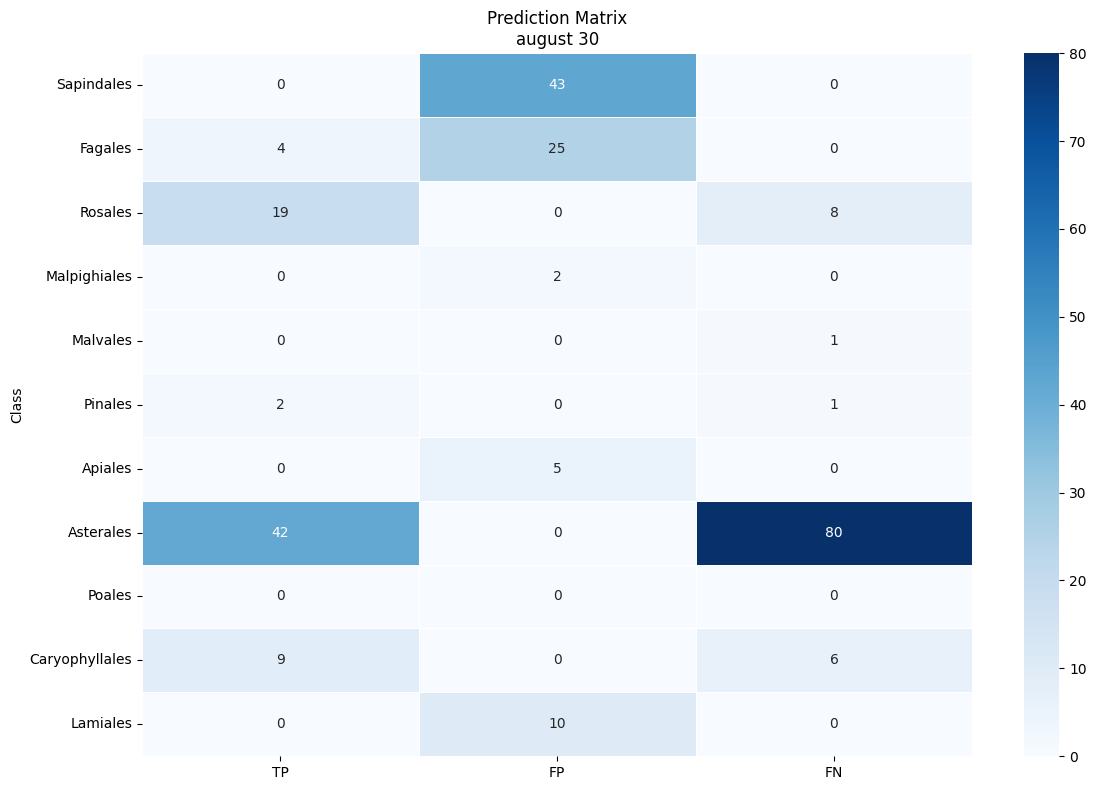

Fagales 1.0
Rosales 0.704
Malvales 0.0
Pinales 0.667
Asterales 0.344
Caryophyllales 0.6
---Sample test---
True Total objets: 204.0, data: {'Sapindales': 0.0, 'Fagales': 1.0, 'Rosales': 60.0, 'Malpighiales': 9.0, 'Malvales': 0.0, 'Pinales': 1.0, 'Apiales': 0.0, 'Asterales': 20.0, 'Poales': 0, 'Caryophyllales': 113.0, 'Lamiales': 0.0}
----------
Pred Total objets: 163.0, data: {'Sapindales': 2.0, 'Fagales': 9.0, 'Rosales': 19.0, 'Malpighiales': 0.0, 'Malvales': 1.0, 'Pinales': 2.0, 'Apiales': 1.0, 'Asterales': 21.0, 'Poales': 1.0, 'Caryophyllales': 93.0, 'Lamiales': 14.0}


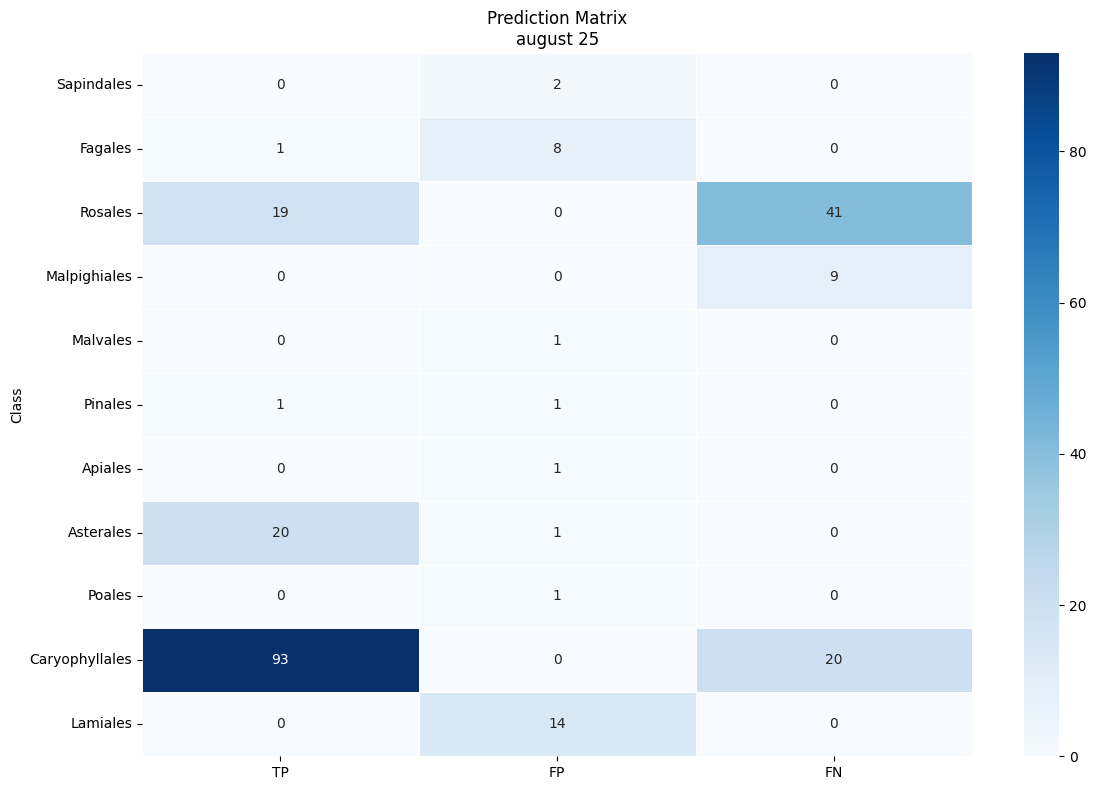

Fagales 1.0
Rosales 0.317
Malpighiales 0.0
Pinales 1.0
Asterales 1.0
Caryophyllales 0.823
---Sample test---
True Total objets: 664.0, data: {'Sapindales': 0.0, 'Fagales': 0.0, 'Rosales': 543.0, 'Malpighiales': 1.0, 'Malvales': 1.0, 'Pinales': 0.0, 'Apiales': 0.0, 'Asterales': 7.0, 'Poales': 0, 'Caryophyllales': 111.0, 'Lamiales': 1.0}
----------
Pred Total objets: 611.0, data: {'Sapindales': 7.0, 'Fagales': 5.0, 'Rosales': 339.0, 'Malpighiales': 8.0, 'Malvales': 0.0, 'Pinales': 0.0, 'Apiales': 2.0, 'Asterales': 51.0, 'Poales': 0.0, 'Caryophyllales': 111.0, 'Lamiales': 88.0}


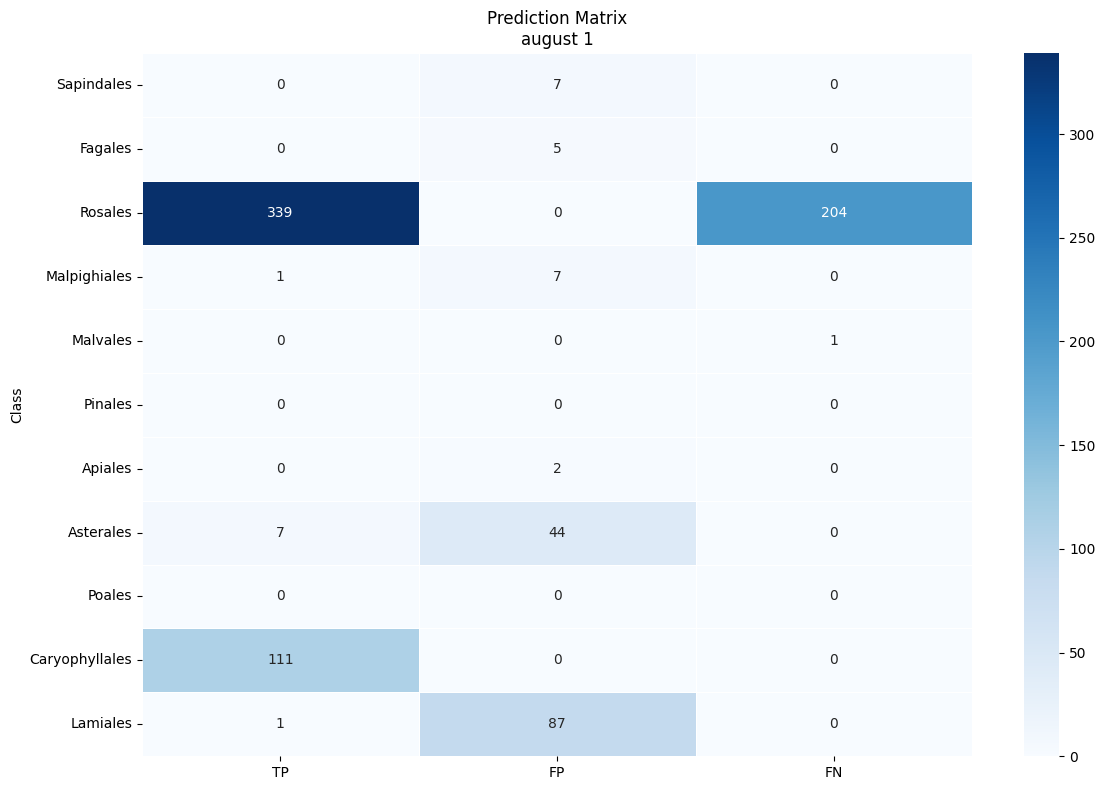

Rosales 0.624
Malpighiales 1.0
Malvales 0.0
Asterales 1.0
Caryophyllales 1.0
Lamiales 1.0
---Sample test---
True Total objets: 80.0, data: {'Sapindales': 27.0, 'Fagales': 35.0, 'Rosales': 10.0, 'Malpighiales': 0.0, 'Malvales': 0.0, 'Pinales': 0.0, 'Apiales': 0.0, 'Asterales': 3.0, 'Poales': 0, 'Caryophyllales': 5.0, 'Lamiales': 0.0}
----------
Pred Total objets: 59.0, data: {'Sapindales': 15.0, 'Fagales': 23.0, 'Rosales': 4.0, 'Malpighiales': 0.0, 'Malvales': 1.0, 'Pinales': 0.0, 'Apiales': 6.0, 'Asterales': 7.0, 'Poales': 0.0, 'Caryophyllales': 1.0, 'Lamiales': 2.0}


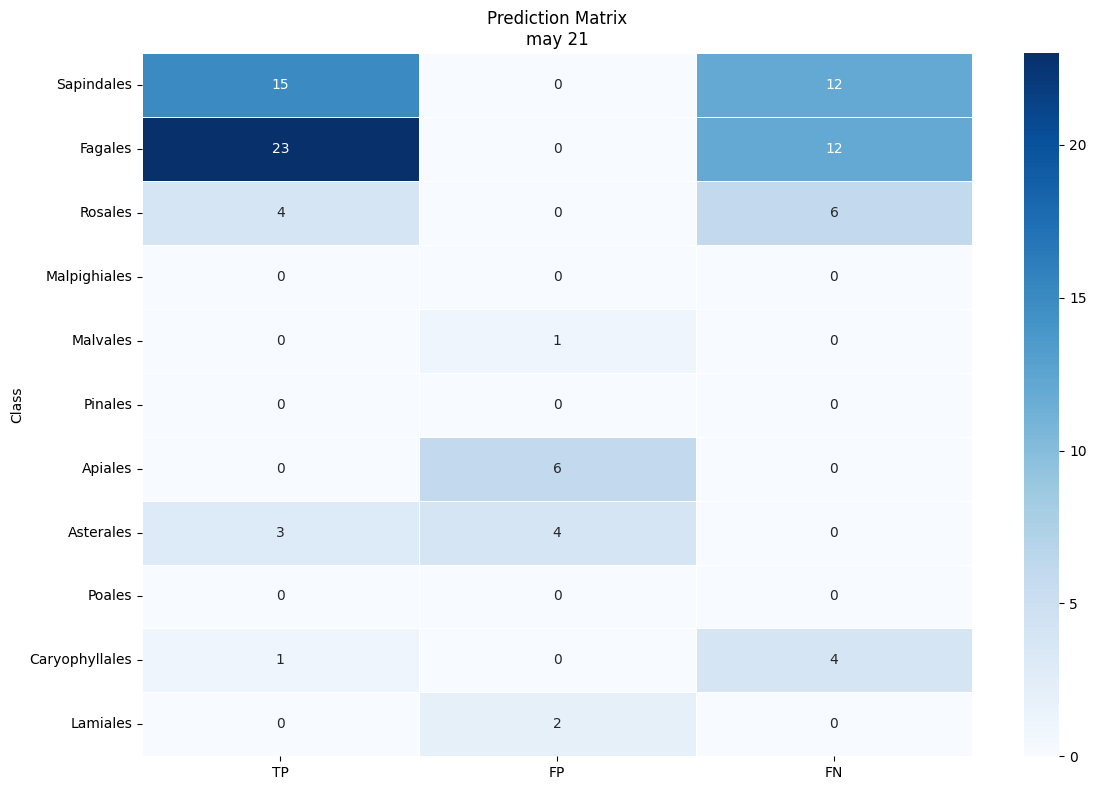

Sapindales 0.556
Fagales 0.657
Rosales 0.4
Asterales 1.0
Caryophyllales 0.2
---Sample test---
True Total objets: 65.0, data: {'Sapindales': 0.0, 'Fagales': 0.0, 'Rosales': 17.0, 'Malpighiales': 0.0, 'Malvales': 0.0, 'Pinales': 0.0, 'Apiales': 0.0, 'Asterales': 0.0, 'Poales': 0, 'Caryophyllales': 48.0, 'Lamiales': 0.0}
----------
Pred Total objets: 42.0, data: {'Sapindales': 0.0, 'Fagales': 0.0, 'Rosales': 12.0, 'Malpighiales': 1.0, 'Malvales': 0.0, 'Pinales': 0.0, 'Apiales': 0.0, 'Asterales': 2.0, 'Poales': 0.0, 'Caryophyllales': 25.0, 'Lamiales': 2.0}


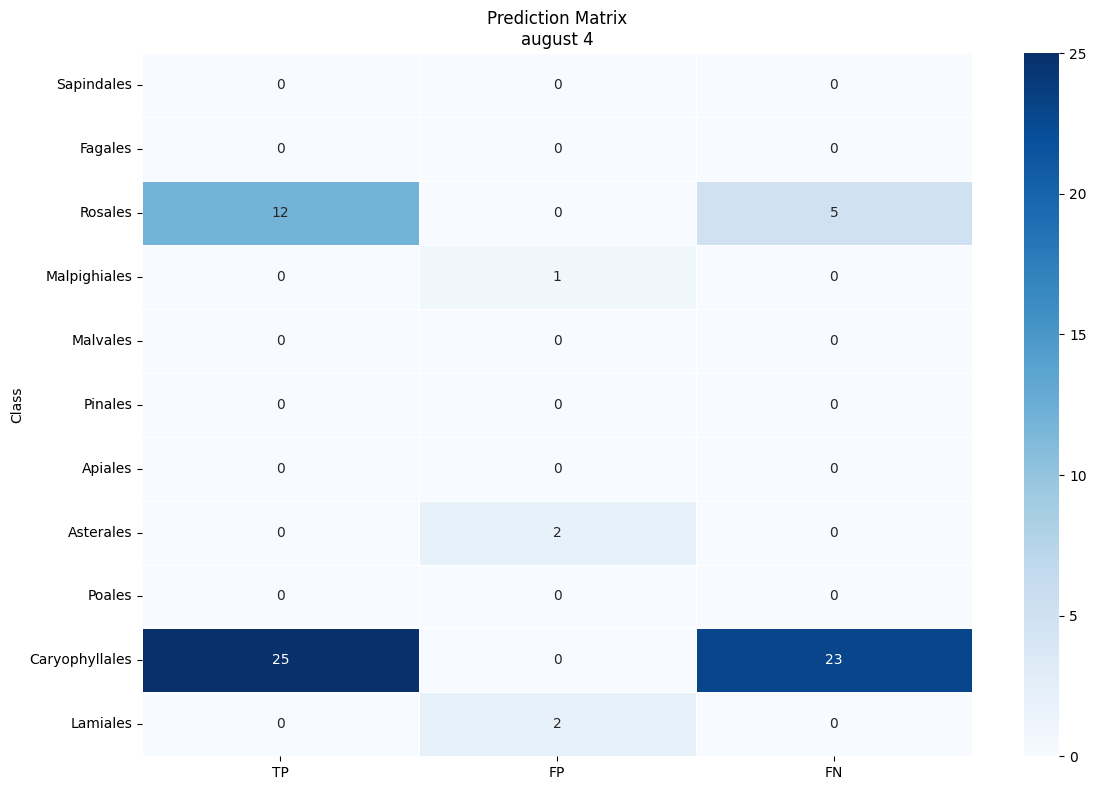

Rosales 0.706
Caryophyllales 0.521
---Sample test---
True Total objets: 223.0, data: {'Sapindales': 0.0, 'Fagales': 0.0, 'Rosales': 142.0, 'Malpighiales': 0.0, 'Malvales': 0.0, 'Pinales': 0.0, 'Apiales': 0.0, 'Asterales': 4.0, 'Poales': 0, 'Caryophyllales': 77.0, 'Lamiales': 0.0}
----------
Pred Total objets: 169.0, data: {'Sapindales': 3.0, 'Fagales': 1.0, 'Rosales': 83.0, 'Malpighiales': 5.0, 'Malvales': 0.0, 'Pinales': 1.0, 'Apiales': 0.0, 'Asterales': 13.0, 'Poales': 0.0, 'Caryophyllales': 61.0, 'Lamiales': 2.0}


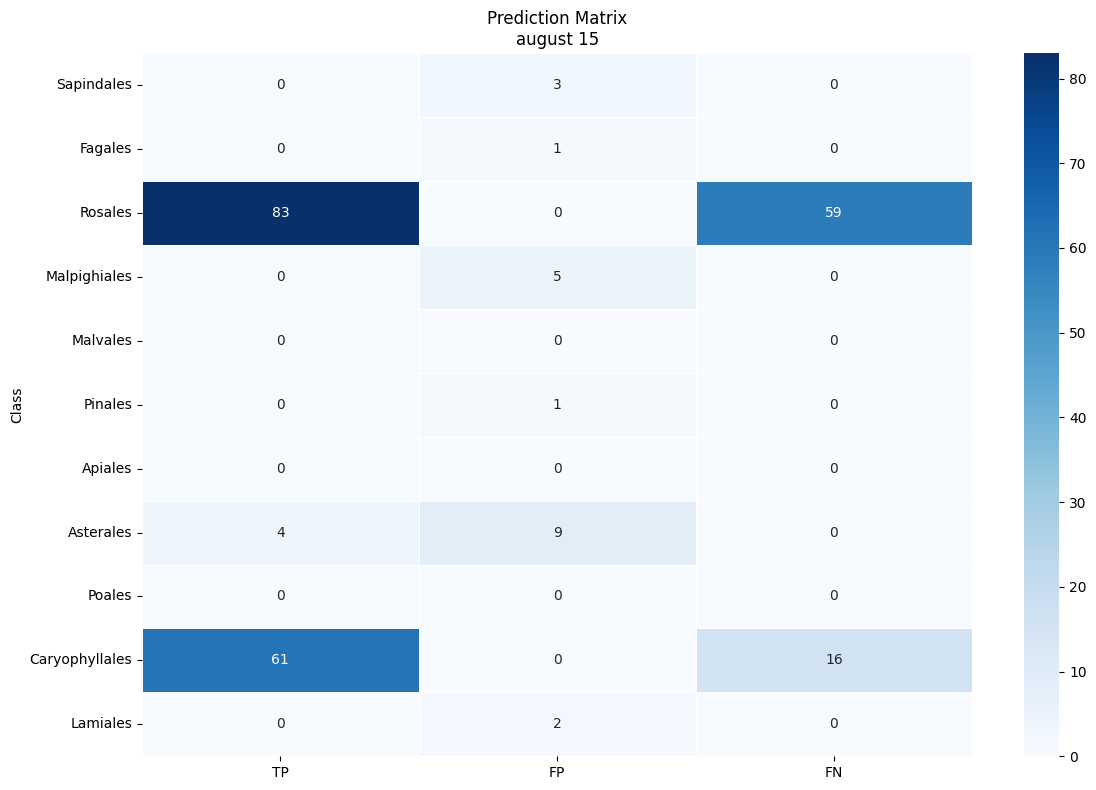

Rosales 0.585
Asterales 1.0
Caryophyllales 0.792
---Sample test---
True Total objets: 221.0, data: {'Sapindales': 0.0, 'Fagales': 1.0, 'Rosales': 52.0, 'Malpighiales': 0.0, 'Malvales': 0.0, 'Pinales': 0.0, 'Apiales': 0.0, 'Asterales': 2.0, 'Poales': 0, 'Caryophyllales': 166.0, 'Lamiales': 0.0}
----------
Pred Total objets: 177.0, data: {'Sapindales': 3.0, 'Fagales': 2.0, 'Rosales': 32.0, 'Malpighiales': 10.0, 'Malvales': 0.0, 'Pinales': 0.0, 'Apiales': 0.0, 'Asterales': 2.0, 'Poales': 0.0, 'Caryophyllales': 118.0, 'Lamiales': 10.0}


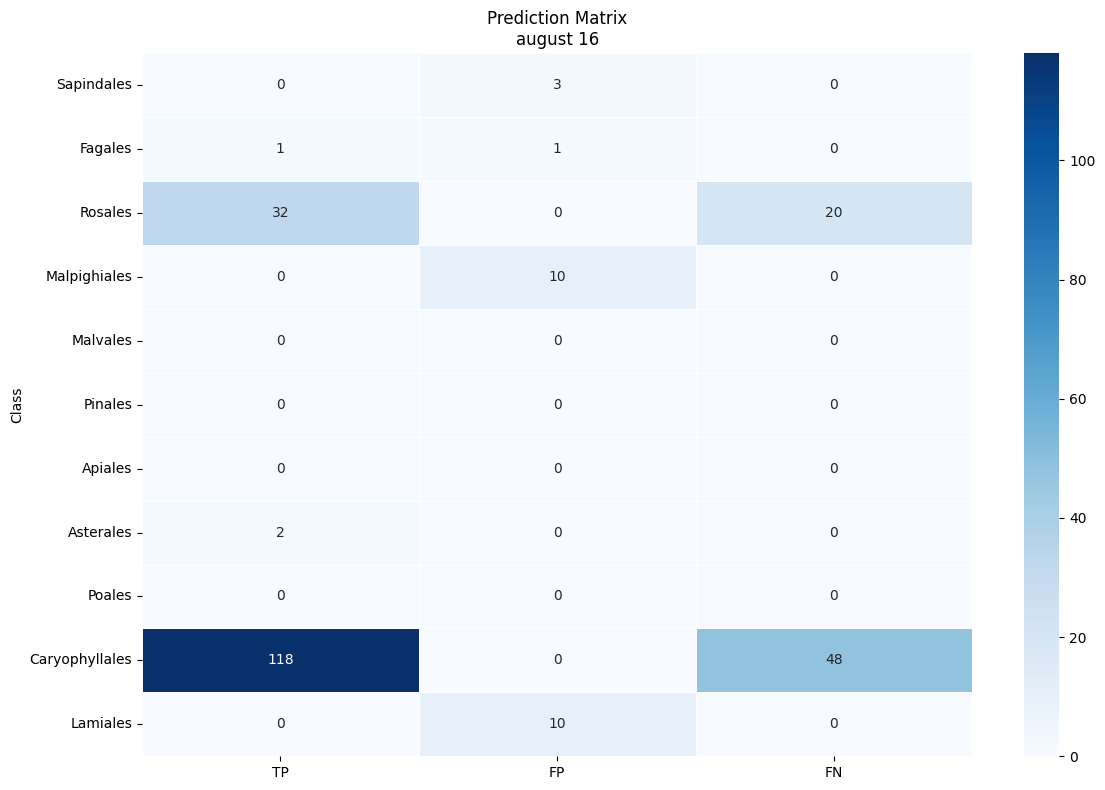

Fagales 1.0
Rosales 0.615
Asterales 1.0
Caryophyllales 0.711
---Sample test---
True Total objets: 299.0, data: {'Sapindales': 5.0, 'Fagales': 8.0, 'Rosales': 33.0, 'Malpighiales': 2.0, 'Malvales': 0.0, 'Pinales': 2.0, 'Apiales': 0.0, 'Asterales': 1.0, 'Poales': 0, 'Caryophyllales': 1.0, 'Lamiales': 247.0}
----------
Pred Total objets: 222.0, data: {'Sapindales': 8.0, 'Fagales': 11.0, 'Rosales': 30.0, 'Malpighiales': 134.0, 'Malvales': 0.0, 'Pinales': 1.0, 'Apiales': 0.0, 'Asterales': 18.0, 'Poales': 3.0, 'Caryophyllales': 0.0, 'Lamiales': 17.0}


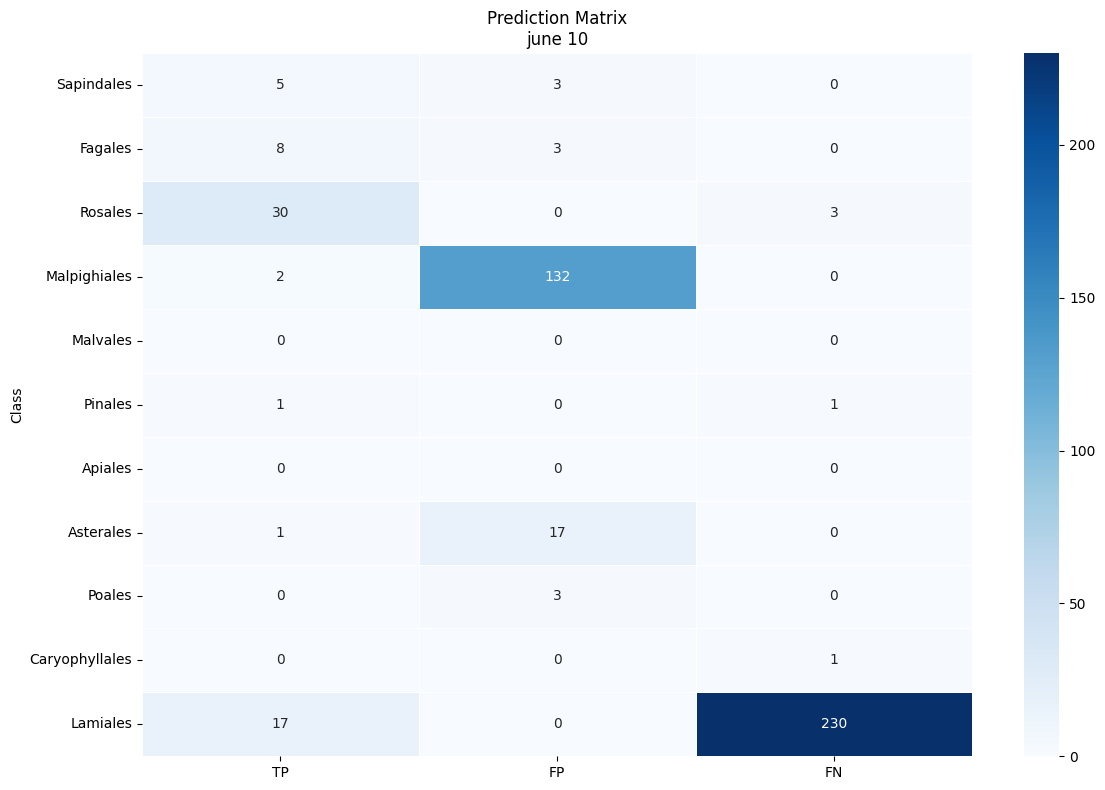

Sapindales 1.0
Fagales 1.0
Rosales 0.909
Malpighiales 1.0
Pinales 0.5
Asterales 1.0
Caryophyllales 0.0
Lamiales 0.069
---Sample test---
True Total objets: 372.0, data: {'Sapindales': 0.0, 'Fagales': 0.0, 'Rosales': 24.0, 'Malpighiales': 0.0, 'Malvales': 0.0, 'Pinales': 0.0, 'Apiales': 0.0, 'Asterales': 5.0, 'Poales': 0, 'Caryophyllales': 3.0, 'Lamiales': 340.0}
----------
Pred Total objets: 247.0, data: {'Sapindales': 13.0, 'Fagales': 8.0, 'Rosales': 19.0, 'Malpighiales': 177.0, 'Malvales': 0.0, 'Pinales': 2.0, 'Apiales': 2.0, 'Asterales': 13.0, 'Poales': 0.0, 'Caryophyllales': 4.0, 'Lamiales': 9.0}


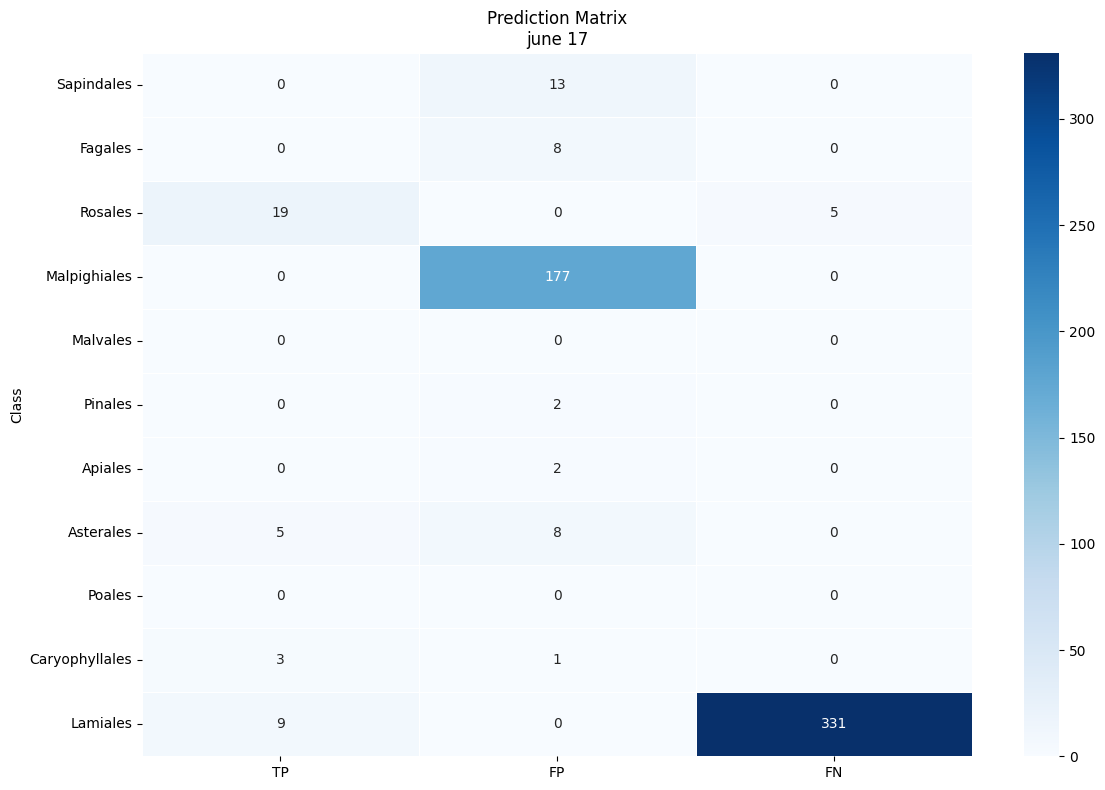

Rosales 0.792
Asterales 1.0
Caryophyllales 1.0
Lamiales 0.026
---Sample test---
True Total objets: 1457.0, data: {'Sapindales': 228.0, 'Fagales': 448.0, 'Rosales': 10.0, 'Malpighiales': 749.0, 'Malvales': 1.0, 'Pinales': 19.0, 'Apiales': 0.0, 'Asterales': 1.0, 'Poales': 0, 'Caryophyllales': 1.0, 'Lamiales': 0.0}
----------
Pred Total objets: 986.0, data: {'Sapindales': 305.0, 'Fagales': 262.0, 'Rosales': 115.0, 'Malpighiales': 146.0, 'Malvales': 0.0, 'Pinales': 17.0, 'Apiales': 2.0, 'Asterales': 134.0, 'Poales': 0.0, 'Caryophyllales': 4.0, 'Lamiales': 1.0}


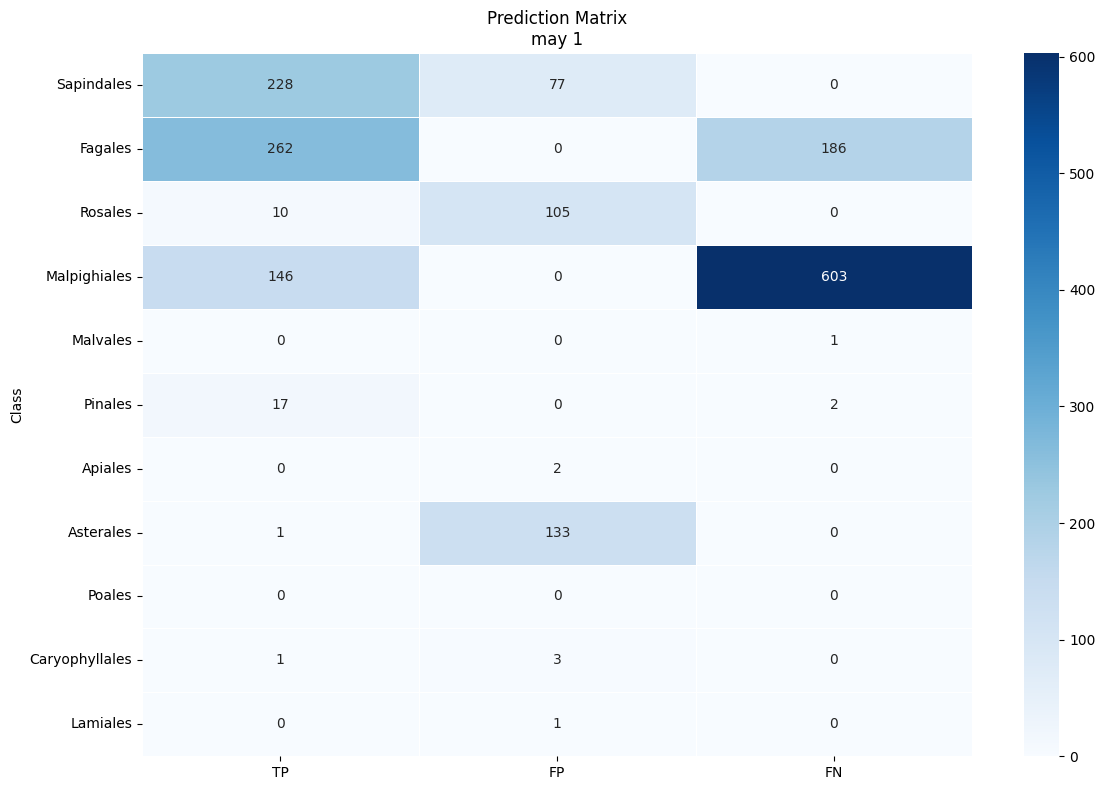

Sapindales 1.0
Fagales 0.585
Rosales 1.0
Malpighiales 0.195
Malvales 0.0
Pinales 0.895
Asterales 1.0
Caryophyllales 1.0


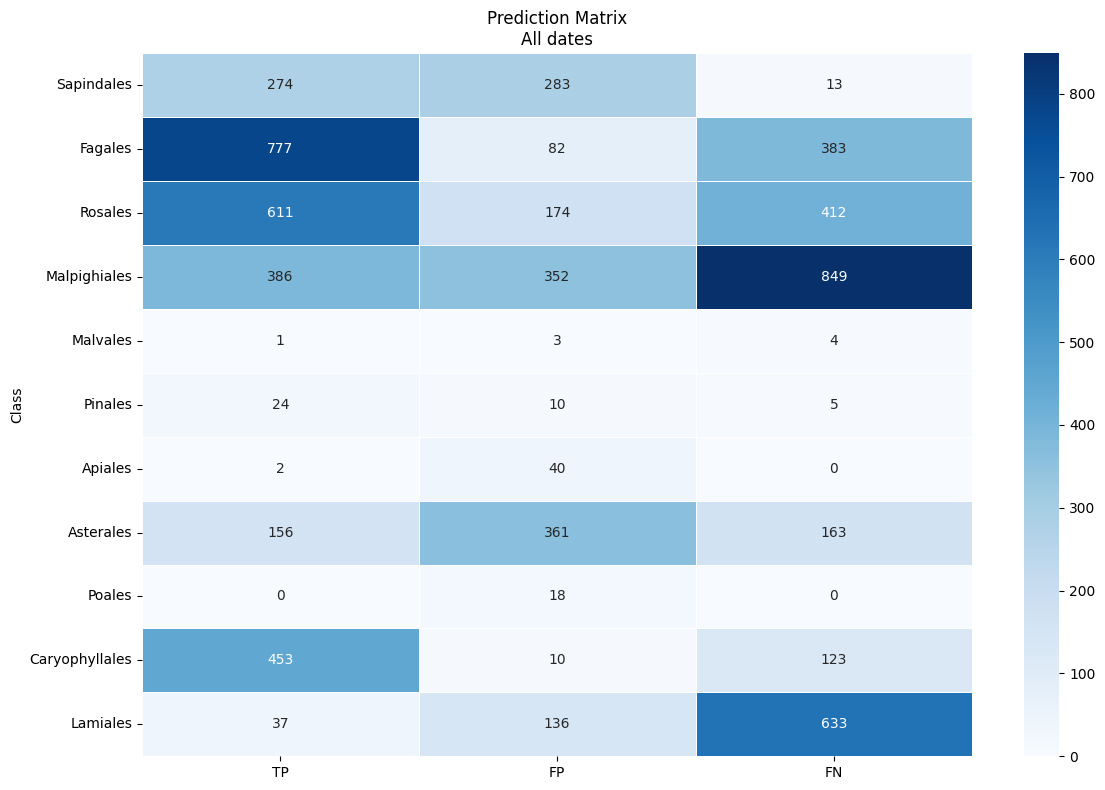

F1 Score: 0.573083403538332


In [36]:
full_confusion_matrices_df = None

for date_idx in model_prediction_df.index:
    prediction:dict = model_prediction_df.loc[date_idx].to_dict()
    groundtruth:dict = expert_estimation_df.loc[date_idx].to_dict()
    assert len(prediction) > 0
    assert len(groundtruth) > 0

    cf_df = analyze_performance_sample_data(groundtruth, prediction, date_idx, all_classes=species_by_ordo.keys(), mapper=species_by_ordo, plot=True)
    if full_confusion_matrices_df is None:
        full_confusion_matrices_df = cf_df
    else:
        full_confusion_matrices_df += cf_df
plot_confusion_matrix(
        full_confusion_matrices_df.iloc[:, 0:3], subtitle="All dates")

evaluate_aggregate_metrics(full_confusion_matrices_df)